In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Seeded random generator for the weights 
rng = np.random.default_rng(1)

In [3]:
# Loading the dataset. The CSV has no header row. Named the columns 
data = pd.read_csv('data-1.csv', header=None)
data.columns = ['x1', 'x2', 'label']

In [4]:
# Making sure the loaded data is what it should be
# There should be 100 points and 3 columns
print("data.shape:", data.shape)    
# Only 0's and 1's at 50/50      
display(data['label'].value_counts())   
# Including ranges (min/max) for the plot later  
display(data.describe())    
# Just confirming the first rows              
data.head()                               

data.shape: (100, 3)


label
1    50
0    50
Name: count, dtype: int64

,x1,x2,label
count,100.000000,100.000000,100.000000
mean,0.520591,0.519660,0.500000
std,0.216743,0.234301,0.502519
min,0.008449,-0.063669,0.000000
25%,0.334825,0.343457,0.000000
50%,0.528265,0.556385,0.500000
75%,0.693588,0.710245,1.000000
max,1.000000,1.000000,1.000000


,x1,x2,label
0,0.78051,-0.063669,1
1,0.28774,0.291390,1
2,0.40714,0.178780,1
3,0.29230,0.421700,1
4,0.50922,0.352560,1


In [5]:
# Splitting into numpy arrays for the training:
#   X = feature matrix (one row per point [x1, x2])
#   y = label vector (0 or 1 for each point)
X = data[['x1', 'x2']].to_numpy()
y = data['label'].to_numpy()

# Making sure the shape is still intact and checking the first row
print("X.shape:", X.shape)
print("y.shape:", y.shape)   
print("X[0]:", X[0])
print("y[0]:", y[0])

X.shape: (100, 2)
y.shape: (100,)
X[0]: [ 0.78051  -0.063669]
y[0]: 1


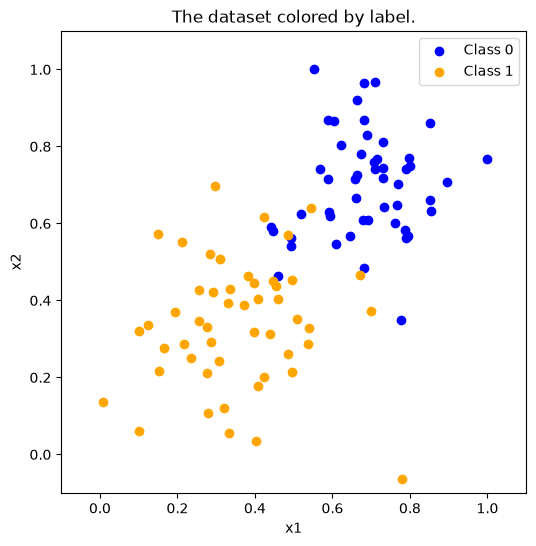

In [24]:
# Scatter plot 
# https://matplotlib.org/stable/users/explain/quick_start.html
# https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xlabel.html
fig, ax = plt.subplots(figsize=(6,6))

# label 0
mask0 = (y == 0)

# label 1
mask1 = (y == 1)

# Scatter for label 0 points
ax.scatter(
    X[mask0,0],
    X[mask0,1],
    color='blue',
    label='Class 0',
)

# Scatter for label 1 points 
ax.scatter(
    X[mask1,0],
    X[mask1,1],
    color='orange',
    label='Class 1',
)

# Axes lables, title, legend
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("The dataset colored by label.")
ax.legend()

# Axes limits
ax.set_xlim(-0.1, 1.1)
ax.set_ylim(-0.1, 1.1)

plt.show()


In [ ]:
# Helper Function for drawing line
# https://numpy.org/doc/stable/reference/generated/numpy.linspace.html
# https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axvline.html


def plot_boundary(ax, w1, w2, b, **kwargs):
    
    low, high = ax.get_xlim()
    x1_values = np.linspace(low, high, 100)
    
    if abs(w2) < 1e-12:
        x1_vertical = -b / w1 
        ax.axvline(x1_vertical, **kwargs)
        return
    
## figure out x2...